Enter 2-bit message (00, 01, 10, 11):  11


Z gate: ACTIVATED
X gate: ACTIVATED

Message sent: 11
Bob decoded: 11
Correct: True


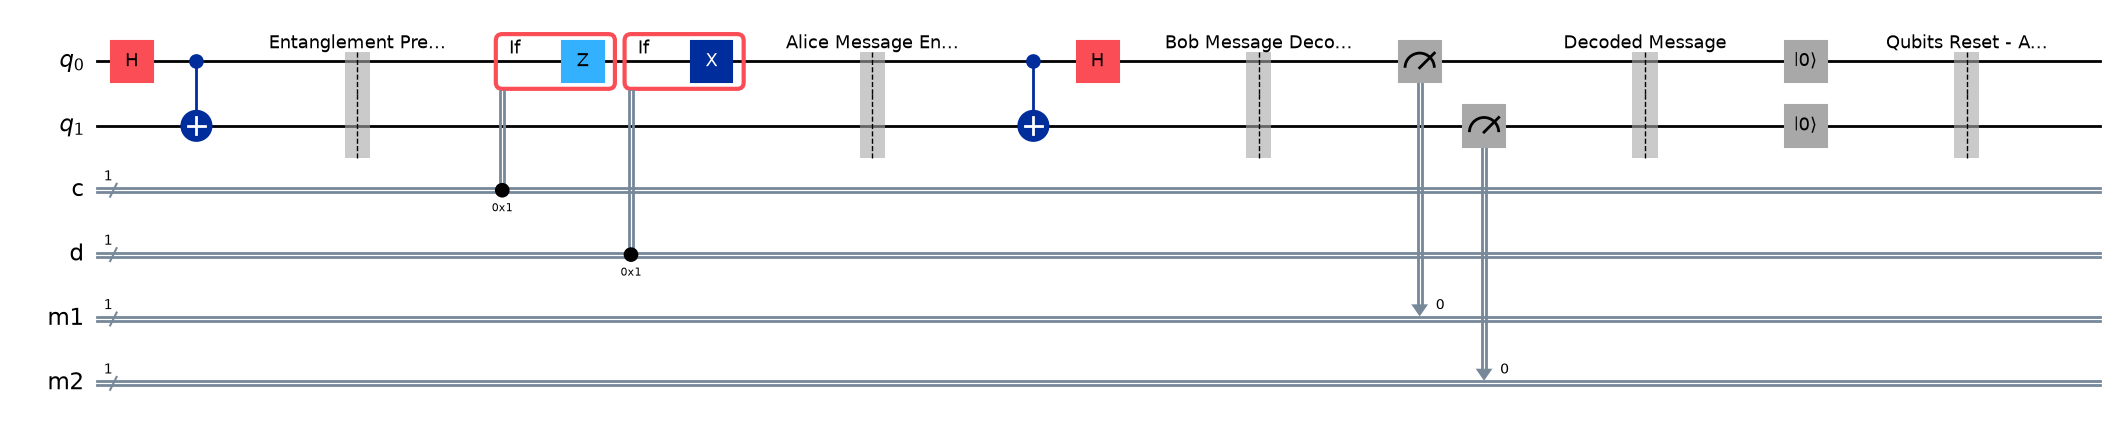

In [1]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.classical import expr
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt
# Input message
message = input("Enter 2-bit message (00, 01, 10, 11): ")

if message not in ["00", "01", "10", "11"]:
    raise ValueError("Enter a valid 2-bit message.")

d = int(message[0])
c = int(message[1])

# Registers
q = QuantumRegister(2, 'q')
d_reg = ClassicalRegister(1, 'c')
c_reg = ClassicalRegister(1, 'd')
m1 = ClassicalRegister(1, 'm1')
m2 = ClassicalRegister(1, 'm2')

qc = QuantumCircuit(q, d_reg, c_reg, m1, m2)

# Store input bits
qc.store(d_reg[0], expr.lift(bool(d)))
qc.store(c_reg[0], expr.lift(bool(c)))

# Gate activation
print("Z gate:", "ACTIVATED" if d else "NOT ACTIVATED")
print("X gate:", "ACTIVATED" if c else "NOT ACTIVATED")

# Create Bell pair
qc.h(q[0])
qc.cx(q[0], q[1])
qc.barrier(label="Entanglement Preparation")

# Alice encoding
with qc.if_test((d_reg, 1)):
    qc.z(q[0])

with qc.if_test((c_reg, 1)):
    qc.x(q[0])
qc.barrier(label="Alice Message Encoding")

# Bob decoding
qc.cx(q[0], q[1])
qc.h(q[0])
qc.barrier(label="Bob Message Decoding")

# Measurements
qc.measure(q[0], m1[0])
qc.measure(q[1], m2[0])
qc.barrier(label="Decoded Message")

# Reset both qubits after measurement
qc.reset(q[0])
qc.reset(q[1])
qc.barrier(label="Qubits Reset - Available for Reuse")

# Run circuit
result = AerSimulator().run(qc, shots=1024).result()
counts = result.get_counts()

# Decode measurement
decoded = max(counts, key=counts.get).split()
decoded = decoded[1] + decoded[0]

print("\nMessage sent:", message)
print("Bob decoded:", decoded)
print("Correct:", decoded == message)


# Draw circuit
plt.show()
qc.draw(output='mpl', fold=-1, scale=1.0)


In [2]:
fig = qc.draw(output="mpl", fold=-1, scale=1.0)
fig.savefig("2_SuperDenseCoding.png", dpi=300, bbox_inches="tight")